In [6]:

import numpy as np
RADIUS = 300

#Data path
PATH_SENSOR_LOCATIONS = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/spatial/data-1775857265051.csv"
EPA_SENSOR_DATA_PATH = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_26_sensor_comparisons/data/boston_pm25_combined.csv"

#Sensor Keys
ROXBURY_KEY = 'DUDLEY SQUARE ROXBURY'
VON_HILLERN_KEY = 'VON HILLERN ST'
CARTER_FIELD_KEY = "Carter Field"
ROBINSON_HALL_KEY = "Robinson Hall"
GAINSBOROUGH_KEY = "Gainsborough Parking Garage"
WEST_VILLAGE_B_KEY = "West Village B"
WORLD_SERIES_KEY = "World Series Way "
AMY_CARTER_FIELD_KEY = "Carter Field — 2"


import pandas as pd

sensor_locations = pd.read_csv(PATH_SENSOR_LOCATIONS)
epa_data = pd.read_csv(EPA_SENSOR_DATA_PATH)
sensor_locations.head()

site_names_epa = np.unique(list(epa_data["site_name"]))

sensor_name_to_location = {}

for key in [ROXBURY_KEY, VON_HILLERN_KEY]:
    sub_data = epa_data[epa_data["site_name"] == key]
    longitude = list(sub_data["lon"])[0]
    latitude = list(sub_data["lat"])[0]

    sensor_name_to_location[key] = [longitude, latitude]


for key in [CARTER_FIELD_KEY, ROBINSON_HALL_KEY, GAINSBOROUGH_KEY, WEST_VILLAGE_B_KEY, WORLD_SERIES_KEY]:
        sub_data = sensor_locations[sensor_locations["ecohub_location"] == key]
        longitude = list(sub_data["lon"])[0]
        latitude = list(sub_data["lat"])[0]

        sensor_name_to_location[key] = [longitude, latitude]
print(site_names_epa)

#Add the Amy Mueller one manually
latitude_amy = 42.3382
longitude_amy = -71.0851

sensor_name_to_location[AMY_CARTER_FIELD_KEY] = [longitude_amy, latitude_amy]


['BOSTON KENMORE SQ' 'Chinatown' 'DUDLEY SQUARE ROXBURY' 'VON HILLERN ST' 'nan']


In [7]:
import osmnx as ox
ox.settings.overpass_url = "https://gall.openstreetmap.de/api"

from alivestreets.network.network_retrieval import get_graph_from_point, export_graph_geojson
from pathlib import Path
from tqdm import tqdm 


PARENT_PATH_GEOJSONS_EXPORT = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison"
import time 
from requests.exceptions import ConnectionError

def graph_with_retry(lat, lon, radius, network_type, tries=5):
    for i in range(tries):
        try:
            return get_graph_from_point(lat=lat, lon=lon, radius=radius, network_type=network_type)
        except ConnectionError:
            if i == tries - 1:
                raise
            time.sleep(10 * (i + 1))

all_locations_keys = list(sensor_name_to_location.keys())
for key in tqdm(all_locations_keys):
    location = sensor_name_to_location[key]
    graph = graph_with_retry(
        lat = location[1],
        lon = location[0],
        radius = RADIUS, 
        network_type = "all"
    )

    export_graph_geojson(
        graph,
        path = Path(PARENT_PATH_GEOJSONS_EXPORT)/f"{key}"/"network.geojson"
    )



 12%|█▎        | 1/8 [00:00<00:05,  1.39it/s]

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison/DUDLEY SQUARE ROXBURY/network.geojson


 25%|██▌       | 2/8 [00:01<00:03,  1.72it/s]

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison/VON HILLERN ST/network.geojson


 38%|███▊      | 3/8 [00:01<00:03,  1.64it/s]

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison/Carter Field/network.geojson


... (6 outputs left out)

 88%|████████▊ | 7/8 [00:04<00:00,  1.46it/s]

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison/World Series Way /network.geojson


100%|██████████| 8/8 [00:05<00:00,  1.49it/s]

Exported: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_16_site_built_environment_comparison/Carter Field — 2/network.geojson


 50%|█████     | 4/8 [00:00<00:00, 16.48it/s]Skipping field name: unsupported OGR type: 5
Skipping field name: unsupported OGR type: 5
100%|██████████| 8/8 [00:00<00:00, 15.80it/s]


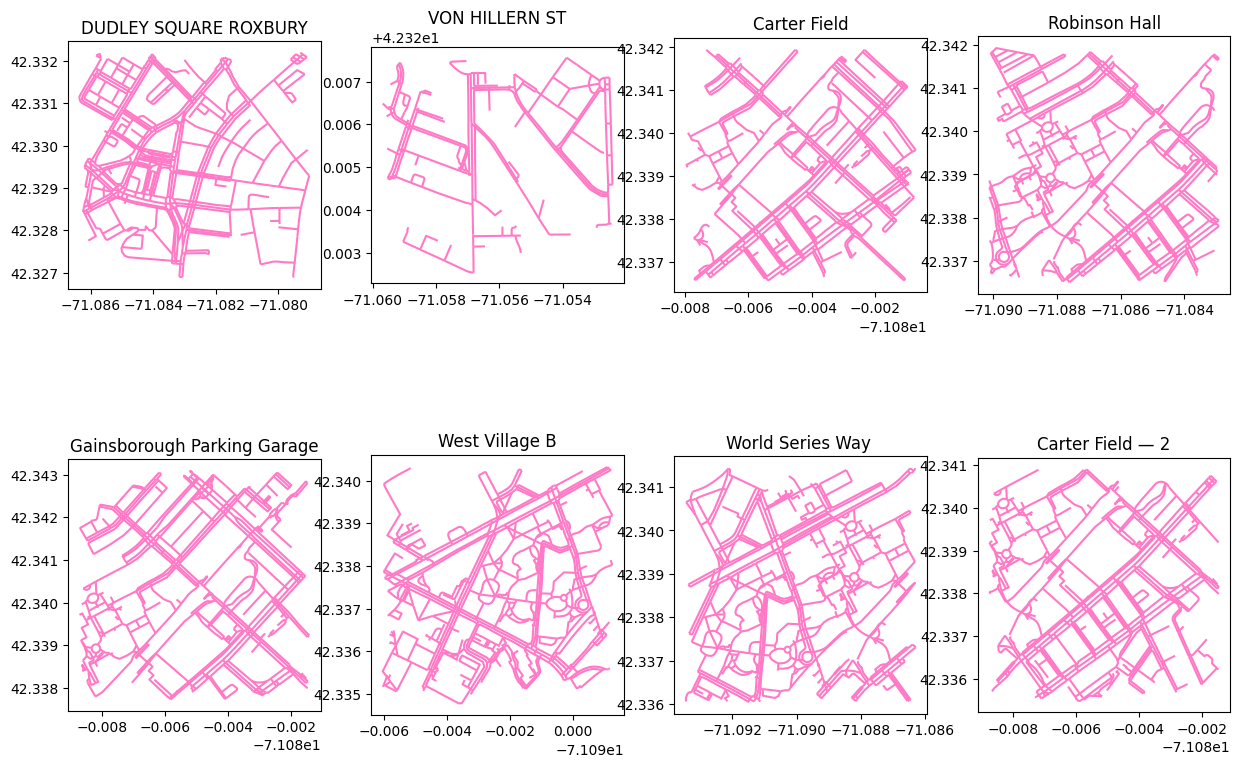

In [8]:
site_name_to_network_path = {}
for key in tqdm(all_locations_keys):
    site_name_to_network_path[key] = Path(PARENT_PATH_GEOJSONS_EXPORT)/f"{key}"/"network.geojson"



import matplotlib.pyplot as plt
import geopandas as gpd
fig, ax = plt.subplots(2,4, figsize = (15,10))
for key in tqdm(all_locations_keys):
    path = site_name_to_network_path[key]
    gdf_network = gpd.read_file(path)
    index = all_locations_keys.index(key)
    row_id = index // 4
    col_id = index % 4
    gdf_network.plot(ax = ax[row_id, col_id], color = "#FF79C6")
    ax[row_id, col_id].set_title(key)


In [9]:
from alivestreets.streetview_collection.streetview_network_collection import StreetViewNetworkCollector
import os
from dotenv import load_dotenv

load_dotenv()

N_SAMPLING_POINTS = 300
API_KEY = ""

image_collector = StreetViewNetworkCollector(
    mode = "sidewalks",
    api_key = API_KEY
)

import json

_original_collect_sidewalk_views = image_collector.street_view_collector.collect_sidewalk_views

def collect_sidewalk_views_with_resume(lat, lon, next_lat, next_lon, output_dir, mode = "both"):
    metadata_path = os.path.join(output_dir, "metadata.json")
    if os.path.exists(metadata_path):
        with open(metadata_path) as f:
            metadata = json.load(f)
        view_paths = [view.get("path") for view in metadata]
        if view_paths and all(path and os.path.exists(path) for path in view_paths):
            return [], metadata
    return _original_collect_sidewalk_views(lat, lon, next_lat, next_lon, output_dir, mode = mode)

image_collector.street_view_collector.collect_sidewalk_views = collect_sidewalk_views_with_resume

site_name_to_imagery_path = {}
for key in tqdm(all_locations_keys):
    imagery_path = Path(PARENT_PATH_GEOJSONS_EXPORT)/f"{key}"/"Imagery"
    site_name_to_imagery_path[key] = imagery_path

    street_sampler = StreetSampler(N_SAMPLING_POINTS)
    street_sampler.open_streets(site_name_to_network_path[key])
    street_sampler.sample_streets_no_intersections()

    image_collector.collect_street_sampler_images(
        street_sampler,
        parent_output_location = imagery_path
    )

    n_images = len(list(imagery_path.rglob("*.jpg")))
    print(f"{key}: {n_images} images")


 12%|█▎        | 1/8 [00:02<00:16,  2.41s/it]

DUDLEY SQUARE ROXBURY: 1154 images


 25%|██▌       | 2/8 [00:03<00:10,  1.79s/it]

VON HILLERN ST: 628 images


 38%|███▊      | 3/8 [00:06<00:10,  2.10s/it]

Carter Field: 1126 images


... (6 outputs left out)

 88%|████████▊ | 7/8 [00:17<00:02,  2.88s/it]

World Series Way : 1368 images


100%|██████████| 8/8 [03:24<00:00, 25.54s/it]

Carter Field — 2: 1174 images
